# Power Curve Analysis
## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Reading in the Datasets

In [2]:
# load in turbine and met masts datasets
scada = pd.read_parquet('../../data/cleaned/scada_data.parquet')
metmasts = pd.read_parquet('../../data/cleaned/metmasts_data.parquet')
reference = pd.read_parquet('../../data/cleaned/reference_power_curve.parquet')

### Creating List of All Turbines

In [3]:
turbines = scada['turbine'].unique()

## Generating Power Curves

In [4]:
def corrected_wind_speed(wind_speed, air_density, ws0 = 7, ws1 = 12, ex0 = 1/3, ex1 = 2/3, standard = 1.225):
    frac = np.clip((wind_speed - ws0) / (ws1 - ws0), 0, 1)
    exponent = ex0 + frac * (ex1 - ex0)
    
    return wind_speed * (air_density / standard) ** exponent

In [5]:
scada['corrected_ws'] = corrected_wind_speed(scada['wind_speed'], scada['air_density'], standard = 1.050817)
reference['corrected_ref_ws'] = corrected_wind_speed(reference['wind_speed_ref'], reference['air_density_ref'], standard = 1.050817)

In [25]:
def avg_power_curve(df_full, turbine, p = 'M', cutin = 3, rated = 15, width = 0.5, wind_speed = 'corrected_ws', min_count = 1, 
                    exclude_target_from_fleet = False):
    # filter to the given wind-speed range.
    valid_ws = (df_full[wind_speed].ge(cutin) & df_full[wind_speed].le(rated))
    df_all = df_full.loc[valid_ws].copy()

    # create a common period and bin definition.
    df_all['period'] = df_all['utc'].dt.to_period(p)
    n_bins = int(np.ceil((rated - cutin) / width))
    df_all['bin'] = np.floor((df_all[wind_speed] - cutin) / width).astype('int64').clip(0, n_bins - 1)

    # target turbine's period-by-bin averages.
    df = df_all.loc[df_all['turbine'].eq(turbine)].copy()

    bin_means = (df.groupby(['period', 'bin'], observed = True).agg(mean_real_power = ('KPI_real_power_ac', 'mean'),
                                                                    mean_theoretical_power = ('KPI_theoretical_power', 'mean'),
                                                                    n = ('KPI_real_power_ac', 'count')).reset_index())

    # fleet reference: mean measured power for each period and bin.
    fleet_data = df_all

    if exclude_target_from_fleet:
        fleet_data = fleet_data.loc[~fleet_data['turbine'].eq(turbine)]

    fleet_means = (fleet_data.groupby(['period', 'bin'], observed = True).agg(mean_fleet_power = ('KPI_real_power_ac', 'mean'),
                                                                              n_fleet = ('KPI_real_power_ac', 'count'),
                                                                              n_fleet_turbines = ('turbine', 'nunique')).reset_index())

    # join the reference values by their matching period and bin.
    bin_means = bin_means.merge(fleet_means, on = ['period', 'bin'], how = 'left', validate = 'one_to_one')

    # wind-speed bin midpoint.
    bin_means[wind_speed] = (cutin + (bin_means['bin'] + 0.5) * width)

    # correct the midpoint for a potentially partial final bin.
    bin_means[wind_speed] = np.minimum(bin_means[wind_speed], rated)

    bin_means['turbine'] = turbine

    # calculate relative differences; invalid references become NaN.
    valid_target = (bin_means['n'].ge(min_count) & bin_means['mean_real_power'].notna())
    valid_theoretical = (valid_target & bin_means['mean_theoretical_power'].gt(0))
    valid_fleet = (valid_target & bin_means['mean_fleet_power'].gt(0))

    bin_means['perc_diff_theoretical'] = np.nan
    bin_means.loc[valid_theoretical, 'perc_diff_theoretical'] = (bin_means.loc[valid_theoretical, 'mean_real_power']
                                                                 / bin_means.loc[valid_theoretical, 'mean_theoretical_power'] - 1)

    bin_means['perc_diff_fleet'] = np.nan
    bin_means.loc[valid_fleet, 'perc_diff_fleet'] = (bin_means.loc[valid_fleet, 'mean_real_power']
                                                     / bin_means.loc[valid_fleet, 'mean_fleet_power'] - 1)

    # average the bin-level relative differences within each period.
    bin_means['avg_perc_diff_theoretical'] = (bin_means.groupby('period', observed = True)['perc_diff_theoretical'].transform('mean'))
    bin_means['avg_perc_diff_fleet'] = (bin_means.groupby('period', observed = True)['perc_diff_fleet'].transform('mean'))

    # number of valid bins contributing to each period's average.
    bin_means['n_valid_theoretical_bins'] = (bin_means.groupby('period', observed = True)['perc_diff_theoretical'].transform('count'))
    bin_means['n_valid_fleet_bins'] = (bin_means.groupby('period', observed = True)['perc_diff_fleet'].transform('count'))

    return bin_means

### Summarizing Every Turbine

In [17]:
summaries = []

for w in turbines:
    res = avg_power_curve(scada, w, p = 'M', cutin = 3, rated = 15, width = 0.5)

    # keep one row per period and turbine
    summary = res[['period', 'turbine', 'avg_perc_diff_theoretical', 'avg_perc_diff_fleet', 'n_valid_theoretical_bins',
                   'n_valid_fleet_bins']].drop_duplicates(subset = ['period', 'turbine'])

    summaries.append(summary)

turbine_summary = pd.concat(summaries, ignore_index = True)

turbine_summary = turbine_summary.sort_values(['period', 'turbine']).reset_index(drop = True)

In [18]:
turbine_summary.shape

(409, 6)

In [19]:
turbine_summary['avg_perc_diff_theoretical'].describe()

count    409.000000
mean       0.688626
std        2.473809
min       -0.704276
25%        0.026872
50%        0.170279
75%        0.394802
max       30.073104
Name: avg_perc_diff_theoretical, dtype: float64

In [20]:
turbine_summary['avg_perc_diff_fleet'].describe()

count    409.000000
mean       0.003589
std        0.180932
min       -0.708515
25%       -0.077534
50%        0.031457
75%        0.126005
max        0.345695
Name: avg_perc_diff_fleet, dtype: float64

In [21]:
# All expected turbine-month combinations
all_periods = scada["utc"].dt.to_period("M").dropna().unique()

expected = pd.MultiIndex.from_product(
    [all_periods, turbines],
    names=["period", "turbine"]
).to_frame(index=False)

# Identify missing combinations
missing = expected.merge(
    turbine_summary[["period", "turbine"]],
    on=["period", "turbine"],
    how="left",
    indicator=True
)

missing = missing[missing["_merge"] == "left_only"].drop(
    columns="_merge"
)

print(f"Expected rows: {len(expected)}")
print(f"Actual rows: {len(turbine_summary)}")
print(f"Missing rows: {len(missing)}")

print(missing.sort_values(["period", "turbine"]).to_string(index=False))

Expected rows: 423
Actual rows: 409
Missing rows: 14
 period turbine
2026-02  WTG169
2026-03  WTG169
2026-04  WTG169
2026-04  WTG183
2026-05  WTG169
2026-05  WTG183
2026-06  WTG169
2026-06  WTG183
2026-07  WTG169
2026-07  WTG183
2026-08  WTG169
2026-08  WTG183
2026-09  WTG169
2026-09  WTG183


### Analyzing WTG159

In [34]:
result = avg_power_curve(scada, 'WTG179', p = 'M', cutin = 3, rated = 15, width = 0.5)

In [35]:
result[result['period'] == '2026-02']

,period,bin,mean_real_power,mean_theoretical_power,n,mean_fleet_power,n_fleet,n_fleet_turbines,corrected_ws,turbine,perc_diff_theoretical,perc_diff_fleet,avg_perc_diff_theoretical,avg_perc_diff_fleet,n_valid_theoretical_bins,n_valid_fleet_bins
24,2026-02,0,14.630977,0.000000,323,18.888310,15440,46,3.25,WTG179,NaN,-0.225395,0.186226,0.040771,23,24
25,2026-02,1,56.103282,10.314452,243,55.283226,13216,46,3.75,WTG179,4.439289,0.014834,0.186226,0.040771,23,24
26,2026-02,2,127.834546,130.560762,233,116.629935,11098,46,4.25,WTG179,-0.020881,0.096070,0.186226,0.040771,23,24
27,2026-02,3,203.636708,196.466513,198,193.430019,9769,46,4.75,WTG179,0.036496,0.052767,0.186226,0.040771,23,24
28,2026-02,4,304.585239,294.995525,168,282.654018,8573,46,5.25,WTG179,0.032508,0.077590,0.186226,0.040771,23,24
29,2026-02,5,400.331048,393.906001,163,393.037776,7455,46,5.75,WTG179,0.016311,0.018556,0.186226,0.040771,23,24
30,2026-02,6,479.289011,522.720170,174,523.209515,6261,46,6.25,WTG179,-0.083087,-0.083944,0.186226,0.040771,23,24
31,2026-02,7,619.480633,668.525078,142,674.538823,5319,46,6.75,WTG179,-0.073362,-0.081623,0.186226,0.040771,23,24
32,2026-02,8,829.316800,824.963234,126,848.027170,4329,46,7.25,WTG179,0.005277,-0.022063,0.186226,0.040771,23,24
33,2026-02,9,968.348401,1008.559383,95,1017.195682,3716,46,7.75,WTG179,-0.039870,-0.048022,0.186226,0.040771,23,24


In [28]:
reference

,model,rated_power_ref,air_density_ref,wind_speed_ref,power_ref,ti_class,corrected_ref_ws
0,GE_2_85MW_103mRD,2850,1.020,3.0,1,normal,2.970382
1,GE_2_85MW_103mRD,2850,1.020,3.5,7,normal,3.465445
2,GE_2_85MW_103mRD,2850,1.020,4.0,63,normal,3.960509
3,GE_2_85MW_103mRD,2850,1.020,4.5,130,normal,4.455573
4,GE_2_85MW_103mRD,2850,1.020,5.0,210,normal,4.950636
...,...,...,...,...,...,...,...
490,GE_2_85MW_103mRD,2850,1.225,23.5,2850,normal,26.029982
491,GE_2_85MW_103mRD,2850,1.225,24.0,2850,normal,26.583811
492,GE_2_85MW_103mRD,2850,1.225,24.5,2850,normal,27.137640
493,GE_2_85MW_103mRD,2850,1.225,25.0,2850,normal,27.691470


In [29]:
month = result[result['period'] == '2026-07']
mean_density = month['air_density'].mean()

reference = reference[
    np.isclose(reference['air_density_ref'], mean_density, atol = .1) & reference['ti_class'].astype(str).str.strip().str.lower().eq('normal')
].copy()

plt.figure(figsize = (10, 5))
plt.plot(month['corrected_ws'], month['mean_real_power'], label = 'Mean Real Power', color = 'cornflowerblue')
plt.plot(month['corrected_ws'], month['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
plt.plot(reference['wind_speed_ref'], reference['power_ref'], color = 'black')
plt.xlim(3, 15)
plt.legend()
plt.xlabel('Wind Speed')
plt.ylabel('Mean Power Output')
plt.title('Mean Power Output by Binned Wind Speed')
plt.grid(alpha = 0.3)
plt.show()

KeyError: 'air_density'

In [36]:
ws_ref = np.sort(ref["wind_speed"].unique())
ref_std = pd.DataFrame({"wind_speed": ws_ref,
                        "power": interp(np.column_stack([ws_ref, np.full_like(ws_ref, 1.225)]))})

plt.scatter(meas["ws_corrected"], meas["power"], s=3, alpha=0.3, label="Measured (density-corrected)")
plt.plot(ref_std["wind_speed"], ref_std["power"], "k-", lw=2, label="Reference @ 1.225 kg/m³")
plt.xlabel("Corrected wind speed (m/s)"); plt.ylabel("Power"); plt.legend(); plt.show()

NameError: name 'ref' is not defined

In [59]:
result = avg_power_curve(scada, 'WTG173', p = 'M', cutin = 3, rated = 15, width = 0.5)

In [54]:
result[result['period'] == '2026-05']

,period,bin,mean_real_power,mean_theoretical_power,n,mean_fleet_power,n_fleet,n_fleet_turbines,corrected_ws,turbine,perc_diff_theoretical,perc_diff_fleet,avg_perc_diff_theoretical,avg_perc_diff_fleet,n_valid_theoretical_bins,n_valid_fleet_bins
95,2026-05,0,16.428232,0.000000,161,17.429310,7595,45,3.25,WTG171,NaN,-0.057436,-0.19026,-0.216474,23,24
96,2026-05,1,53.516062,16.252637,146,52.502630,7626,45,3.75,WTG171,2.292762,0.019303,-0.19026,-0.216474,23,24
97,2026-05,2,123.266939,130.247532,144,110.487336,7457,45,4.25,WTG171,-0.053595,0.115666,-0.19026,-0.216474,23,24
98,2026-05,3,151.185960,211.864604,140,181.532440,7159,45,4.75,WTG171,-0.286403,-0.167168,-0.19026,-0.216474,23,24
99,2026-05,4,220.535192,301.025571,164,262.071911,6812,45,5.25,WTG171,-0.267387,-0.158494,-0.19026,-0.216474,23,24
100,2026-05,5,293.081748,419.860093,157,364.743899,6767,45,5.75,WTG171,-0.301954,-0.196473,-0.19026,-0.216474,23,24
101,2026-05,6,361.656667,529.808098,153,480.814655,6521,45,6.25,WTG171,-0.317382,-0.247825,-0.19026,-0.216474,23,24
102,2026-05,7,424.510585,669.736967,146,613.763583,6656,45,6.75,WTG171,-0.366153,-0.308348,-0.19026,-0.216474,23,24
103,2026-05,8,562.168168,841.638474,147,771.633310,6936,45,7.25,WTG171,-0.332055,-0.271457,-0.19026,-0.216474,23,24
104,2026-05,9,638.055149,1022.733298,172,940.608033,6486,45,7.75,WTG171,-0.376128,-0.321657,-0.19026,-0.216474,23,24


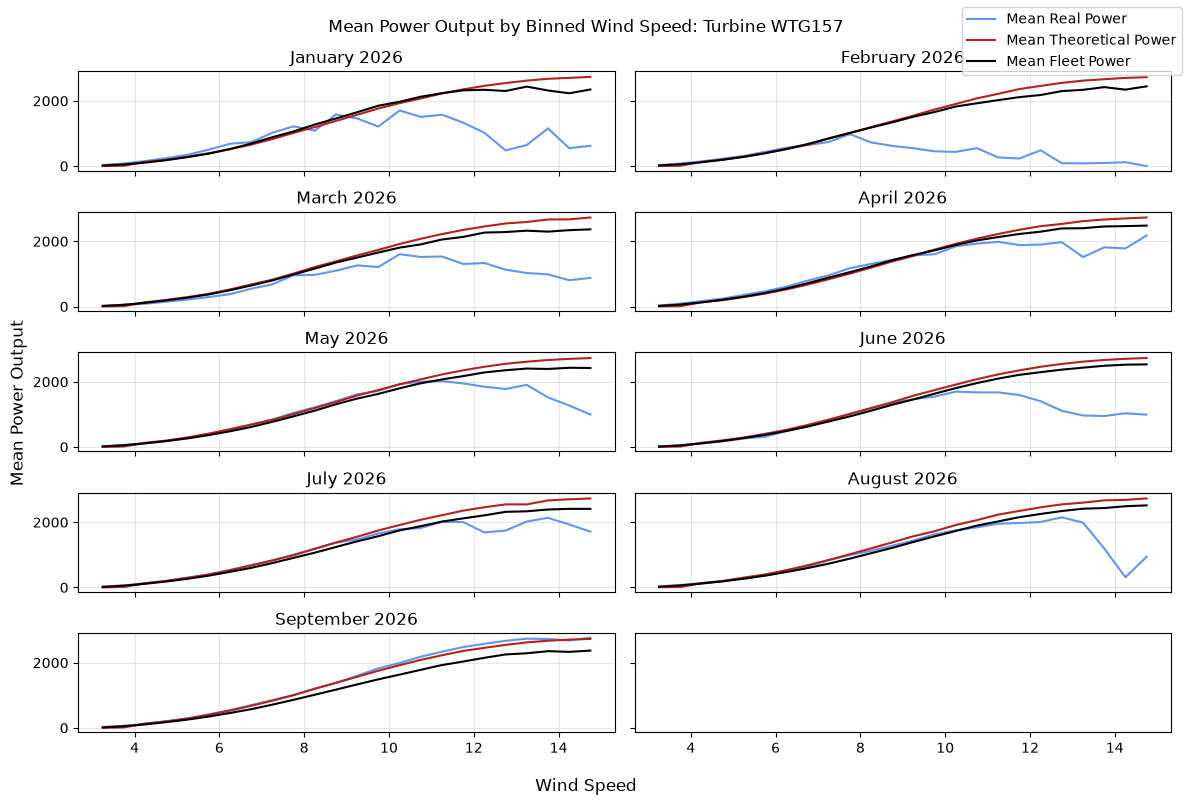

In [60]:
months = result['period'].unique()

fig, axes = plt.subplots(5, 2, figsize = (12, 8), sharex = True, sharey = True)

for ax, month in zip(axes.flat, months):
    grp = result[result['period'] == month]
    ax.plot(grp['corrected_ws'], grp['mean_real_power'], label = 'Mean Real Power', color = 'cornflowerblue')
    ax.plot(grp['corrected_ws'], grp['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
    ax.plot(grp['corrected_ws'], grp['mean_fleet_power'], label = 'Mean Fleet Power', color = 'black')
    ax.set_title(month.strftime('%B %Y'))
    ax.grid(alpha = 0.3)

fig.supxlabel('Wind Speed')
fig.supylabel('Mean Power Output')
fig.suptitle('Mean Power Output by Binned Wind Speed: Turbine WTG157')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper right')

plt.tight_layout()
plt.show()